# A 12-month NDVI time series for one farm field from Sentinel-2 COGs on AWS

Sentinel-2 photographs every field on Earth every few days, and the [Sentinel-2 L2A Cloud-Optimized GeoTIFFs on AWS](https://registry.opendata.aws/sentinel-2-l2a-cogs/) make it free to read. For a smallholder field of a hectare or two, you do not need whole scenes: you need about a hundred 10 m pixels per pass, and an honest answer to one question, *could the satellite actually see this field today?*

This notebook builds a year of field-level NDVI for one field near Katol, Nagpur district, India:

1. find every Sentinel-2 L2A pass over the field with the Earth Search STAC API
2. read only a small window of the red, near-infrared and scene-classification bands straight from the COGs (no AWS account, no scene downloads)
3. decide per pass whether the **field** (not the scene) was clear
4. compare the field with the land around it, and flag thin haze the cloud mask missed

The functions live in [`field_ndvi.py`](field_ndvi.py) in this repository. The same method produced the open dataset at [varshakrishi.com/open-data](https://www.varshakrishi.com/open-data) (CC BY 4.0).

The example polygon is a 1-hectare square around that dataset's published location, **not** the field's boundary (withheld to protect the landholder's privacy), so the numbers here differ slightly from the published file. Use your own polygon by changing `example/field.geojson`.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import field_ndvi as fn

field = json.load(open("example/field.geojson"))["features"][0]["geometry"]
items = fn.one_per_date(fn.search(field, "2025-10-07", "2026-10-12"), tile="44QKJ")
print(len(items), "Sentinel-2 passes;", items[0]["id"], "...", items[-1]["id"])

91 Sentinel-2 passes; S2B_44QKJ_20251007_0_L2A ... S2B_44QKJ_20261012_0_L2A


## Two tiles, one field

Katol sits where MGRS tiles 44QKJ and 43QHD overlap, so most passes appear twice. `one_per_date()` keeps one scene per date from the main tile and adds any pass that only the other tile recorded (here, 28 August 2026). Mixing tiles is safe because `field_pass()` re-projects the polygon into each scene's own UTM zone.

In [2]:
from collections import Counter
Counter(i["id"].split("_")[1] for i in items)

Counter({'44QKJ': 90, '43QHD': 1})

## The BOA offset

Since processing baseline 04.00 (January 2022), L2A reflectance values carry a +1000 offset. NDVI computed on the raw values is biased low, so `fn.boa_offset()` removes it unless the item says Earth Search has already done so (`earthsearch:boa_offset_applied`).

In [3]:
it = items[0]
print(it["properties"].get("s2:processing_baseline"), it["properties"].get("earthsearch:boa_offset_applied"), "-> offset", fn.boa_offset(it))

05.11 True -> offset 0.0


## One pass, read from the COGs

`field_pass()` reads B04, B08 and SCL for a window covering the field plus 500 m, masks usable pixels (SCL class 4, vegetation, or 5, bare soil), and summarises the field and its neighbourhood. Only the needed byte ranges of each COG are fetched over HTTP.

In [4]:
fn.field_pass(items[1], field)

{'date': '2025-10-12', 'scene_id': 'S2C_44QKJ_20251012_0_L2A', 'scene_cloud_pct': 1.4, 'field_pixels': 100, 'field_valid_fraction': 1.0, 'field_ndvi_mean': 0.668, 'neighbourhood_ndvi_median': 0.75}

## Every pass for a year

This takes a few minutes: three small reads per pass.

In [5]:
rows = []
for it in items:
    rows.append(fn.field_pass(it, field))
fn.flag_haze(rows)
df = pd.DataFrame(rows)
df["date"] = pd.to_datetime(df["date"])
for c in ("field_ndvi_mean", "neighbourhood_ndvi_median"):
    df[c] = pd.to_numeric(df[c], errors="coerce")
df.to_csv("example/field_ndvi_2025-2026.csv", index=False)
df["status"].value_counts()

status
clear                      58
field_not_clear            31
excluded_suspected_haze     2
Name: count, dtype: int64

## Scene cloud cover is a poor guide to one field

The scene's `eo:cloud_cover` describes a 110 km tile. What matters is the share of *this field's* pixels the scene classification layer marks usable.

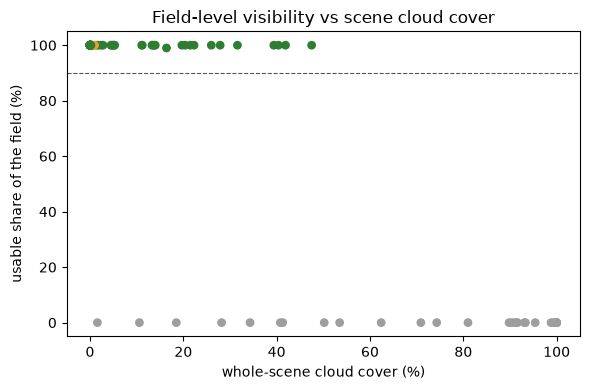

,date,scene_cloud_pct,field_valid_fraction
19,2025-12-21,47.5,1.0
58,2026-06-09,40.4,1.0
81,2026-09-07,41.9,1.0


In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
colors = df["status"].map({"clear": "#2E7D32", "field_not_clear": "#9E9E9E", "excluded_suspected_haze": "#F29A2E"})
ax.scatter(df["scene_cloud_pct"], df["field_valid_fraction"] * 100, c=colors, s=28)
ax.axhline(90, color="#555", lw=0.8, ls="--")
ax.set_xlabel("whole-scene cloud cover (%)"); ax.set_ylabel("usable share of the field (%)")
ax.set_title("Field-level visibility vs scene cloud cover")
plt.tight_layout(); plt.show()
df.loc[(df.scene_cloud_pct > 40) & (df.status == "clear"), ["date", "scene_cloud_pct", "field_valid_fraction"]]

## The series: the field against its neighbourhood

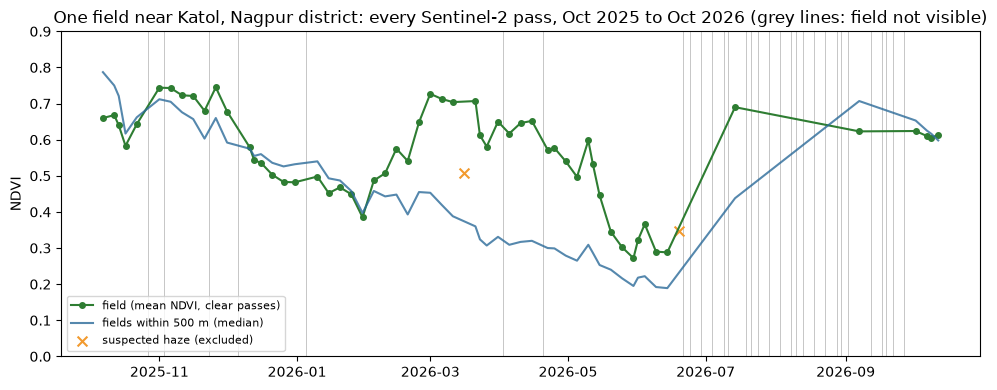

In [7]:
clear, haze = df[df.status == "clear"], df[df.status == "excluded_suspected_haze"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(clear.date, clear.field_ndvi_mean, "-o", ms=4, color="#2E7D32", label="field (mean NDVI, clear passes)")
ax.plot(clear.date, clear.neighbourhood_ndvi_median, "-", color="#2B6A99", alpha=.8, label="fields within 500 m (median)")
ax.scatter(haze.date, haze.field_ndvi_mean, marker="x", color="#F29A2E", s=50, label="suspected haze (excluded)")
for d in df[df.status == "field_not_clear"].date:
    ax.axvline(d, color="#BDBDBD", lw=0.6, zorder=0)
ax.set_ylabel("NDVI"); ax.set_ylim(0, 0.9); ax.legend(loc="lower left", fontsize=8)
ax.set_title("One field near Katol, Nagpur district: every Sentinel-2 pass, Oct 2025 to Oct 2026 (grey lines: field not visible)")
plt.tight_layout(); plt.show()

## A field falling faster than its neighbours

In May 2026 the field dried faster than the land around it. A ten-day change against the neighbourhood's change is the kind of signal a weekly field message can be built on.

In [8]:
may = df.set_index(df.date.dt.strftime("%Y-%m-%d")).loc[["2026-05-10", "2026-05-20"], ["field_ndvi_mean", "neighbourhood_ndvi_median"]]
drop = (1 - may.iloc[1] / may.iloc[0]) * 100
print(may, "\n\nten-day fall: field {:.0f}%, neighbourhood {:.0f}%".format(drop.iloc[0], drop.iloc[1]))

            field_ndvi_mean  neighbourhood_ndvi_median
date                                                  
2026-05-10            0.598                      0.309
2026-05-20            0.345                      0.240 

ten-day fall: field 42%, neighbourhood 22%


## The monsoon blind spot

Optical satellites cannot see through monsoon cloud. Count the passes from mid-August to mid-October on which the field was usable.

In [9]:
m = df[(df.date >= "2026-08-17") & (df.date <= "2026-10-12")]
print(len(m), "passes,", int((m.status == "clear").sum()), "with a clear view of the field")

15 passes, 5 with a clear view of the field


## Compare with the published open dataset

The published file uses the field's own boundary, so expect small differences.

In [10]:
pub = pd.read_csv("https://www.varshakrishi.com/open-data/katol-field-ndvi-2025-2026.csv", parse_dates=["date"])
both = df.merge(pub, on="date", suffixes=("_square", "_field")).dropna(subset=["field_ndvi_mean_square", "field_ndvi_mean_field"])
print(len(pub), "published passes;", len(both), "clear in both; mean |difference| = {:.3f} NDVI".format(
    (both.field_ndvi_mean_square - both.field_ndvi_mean_field).abs().mean()))

91 published passes; 59 clear in both; mean |difference| = 0.030 NDVI


## Notes and limits

* NDVI is a greenness index, not a diagnosis: a fall can be water stress, harvest, pruning, pests or a new crop.
* The SCL mask misses thin haze; the haze flag catches large dips but not small ones.
* Fields smaller than about half a hectare have too few pure pixels once edges are excluded.
* For the monsoon, add Sentinel-1 radar, which sees through cloud.

Data credit: contains modified Copernicus Sentinel-2 data 2025-2026, via the Registry of Open Data on AWS (Element 84 Earth Search). Code: MIT. Written by [VarshaKrishi](https://www.varshakrishi.com), which builds weekly field-level crop advice for Indian farmers.